# Predictive Maintenance for a Smart Manufacturing Rig
**HETA Take-Home Task**  
Dataset: `rig_sensor_fail.csv` + `rig_sensor_no_failure.csv`

## 0. Setup & Imports

In [1]:
# Core data handling and visualisation
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
PALETTE = {"No Failure": "#2E86AB", "Failure": "#E84855"}

print("All imports successful.")

All imports successful.


---
## 1. Data Understanding

We receive two separate CSV files — one containing failure snapshots and one containing normal operation snapshots. The first job is to combine them into a single labelled dataset, check data quality, and understand how the sensors behave before attempting any modelling.

### 1.1 Load & Label Data

In [2]:
# Load labelled CSVs and combine into a single dataset
fail = pd.read_csv('rig_sensor_fail.csv')
nofail = pd.read_csv('rig_sensor_no failure.csv')

# Label sources (1 = failure, 0 = normal)
fail['failure'] = 1
nofail['failure'] = 0

# Concatenate and ensure timestamps are parsed (coerce invalid entries)
df = pd.concat([fail, nofail], ignore_index=True)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp']).sort_values('timestamp').reset_index(drop=True)

print(f'Dataset shape : {df.shape}')
print(f'Date range    : {df.timestamp.min()} to {df.timestamp.max()}')
print('Null values   :', df.isnull().sum().to_dict())
df.head()

Dataset shape : (10000, 6)
Date range    : 2025-01-01 09:00:00 to 2025-01-08 07:39:00
Null values   : {'timestamp': 0, 'temperature': 0, 'vibration': 0, 'torque': 0, 'flow': 0, 'failure': 0}


,timestamp,temperature,vibration,torque,flow,failure
0,2025-01-01 09:00:00,308.6,0.2522,42.8,15.662,0
1,2025-01-01 09:01:00,308.7,0.6665,46.3,13.560,0
2,2025-01-01 09:02:00,308.5,0.5762,49.4,15.355,0
3,2025-01-01 09:03:00,308.6,0.0546,39.5,14.800,0
4,2025-01-01 09:04:00,308.7,0.2004,40.0,13.104,0


### 1.2 Class Balance

With 339 failures out of 10,000 rows the dataset is severely imbalanced at 28:1. Significant class imbalance means accuracy alone is a misleading metric — a model that predicts no failure for every row scores 96.6% accuracy while catching nothing. We must use ROC-AUC and PR-AUC instead.

failure
0    9661
1     339
Name: count, dtype: int64

Class imbalance ratio: 28.5:1  (no-failure : failure)


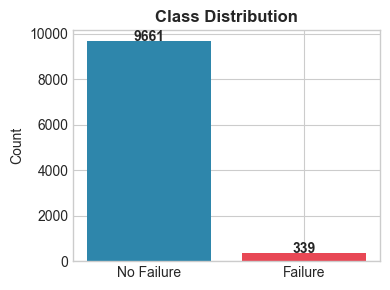

In [3]:
# Count each class and plot the imbalance
counts = df['failure'].value_counts()
print(counts)
print(f'\nClass imbalance ratio: {counts[0]/counts[1]:.1f}:1  (no-failure : failure)')

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(['No Failure', 'Failure'], counts.values,
       color=[PALETTE['No Failure'], PALETTE['Failure']])
ax.set_title('Class Distribution', fontweight='bold')
ax.set_ylabel('Count')
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


### 1.3 Sensor Distributions by Class

Plotting the distribution of each sensor reading split by outcome reveals where the classes separate. Vibration and torque show the clearest separation — failure readings sit noticeably higher. Temperature and flow distributions overlap heavily, making them weaker standalone predictors.

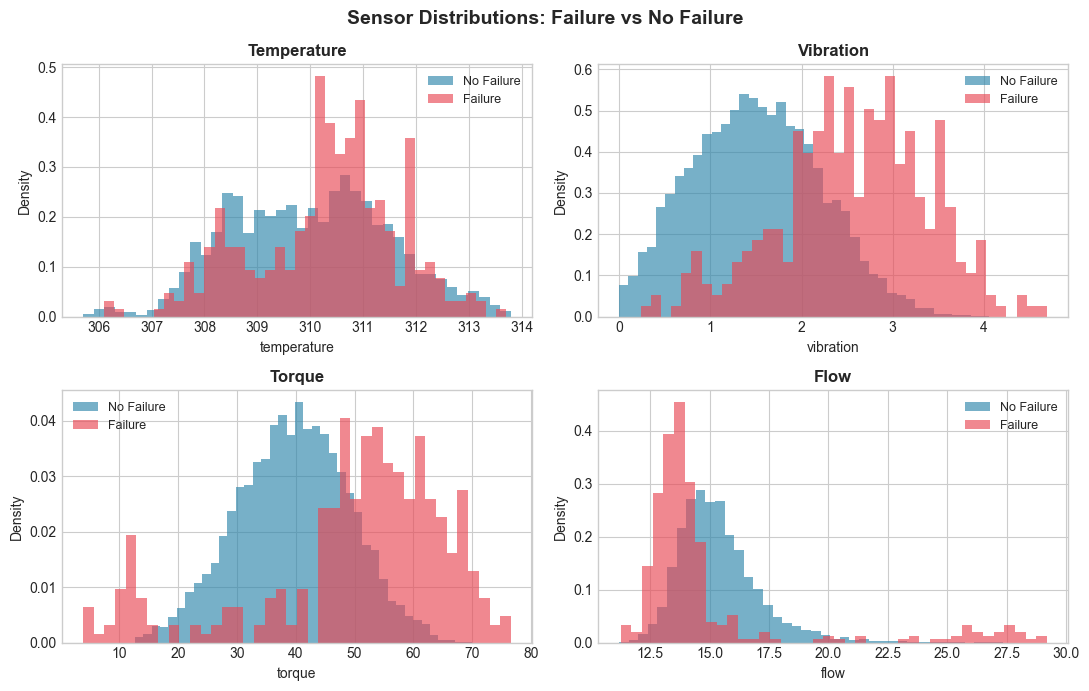

In [4]:
# Overlapping histograms — compare sensor distributions during failure vs normal
features = ['temperature', 'vibration', 'torque', 'flow']

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
fig.suptitle('Sensor Distributions: Failure vs No Failure', fontsize=14, fontweight='bold')

for ax, feat in zip(axes.flatten(), features):
    for val, col, lab in zip([0, 1],
                              [PALETTE['No Failure'], PALETTE['Failure']],
                              ['No Failure', 'Failure']):
        ax.hist(df[df.failure == val][feat], bins=40, alpha=0.65,
                color=col, label=lab, density=True)
    ax.set_title(feat.capitalize(), fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Density')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


### 1.4 Descriptive Statistics by Class

Mean and standard deviation broken down by outcome confirm which sensors show the largest differences between failure and normal operation.

In [5]:
# Summary statistics split by outcome — reveals mean differences per sensor
print('=== Failure = 1 ===')
print(df[df.failure == 1][features].describe().round(2))

print('\n=== Failure = 0 ===')
print(df[df.failure == 0][features].describe().round(2))

print('\n=== Mean difference (failure minus no failure) ===')
print((df[df.failure==1][features].mean() - df[df.failure==0][features].mean()).round(3))

=== Failure = 1 ===
       temperature  vibration  torque    flow
count       339.00     339.00  339.00  339.00
mean        310.29       2.57   50.17   14.97
std           1.36       0.82   16.37    3.93
min         306.10       0.24    3.80   11.26
25%         309.50       2.10   45.95   13.10
50%         310.40       2.58   53.70   13.70
75%         311.20       3.15   61.20   14.47
max         313.70       4.69   76.60   29.20

=== Failure = 0 ===
       temperature  vibration   torque     flow
count      9661.00    9661.00  9661.00  9661.00
mean        310.00       1.51    39.63    15.40
std           1.49       0.70     9.47     1.75
min         305.70       0.00    12.60    11.18
25%         308.80       0.98    33.10    14.22
50%         310.00       1.49    39.90    15.12
75%         311.10       2.00    46.30    16.21
max         313.80       4.06    70.00    27.35

=== Mean difference (failure minus no failure) ===
temperature     0.295
vibration       1.068
torque         10

### 1.5 Correlation with Failure Label

Vibration and torque are the strongest individual predictors of failure. Their product (`vib_torque`) is engineered in Section 2.3 to capture the combined mechanical stress signal, which is more informative than either sensor alone.

In [6]:
# Pearson correlation between each sensor and the failure label
corr = df[features + ['failure']].corr()['failure'].drop('failure').sort_values(key=abs, ascending=False)
print('Pearson correlation (r) with failure label:')
print(corr.round(4))


Pearson correlation (r) with failure label:
vibration      0.2647
torque         0.1913
flow          -0.0412
temperature    0.0359
Name: failure, dtype: float64


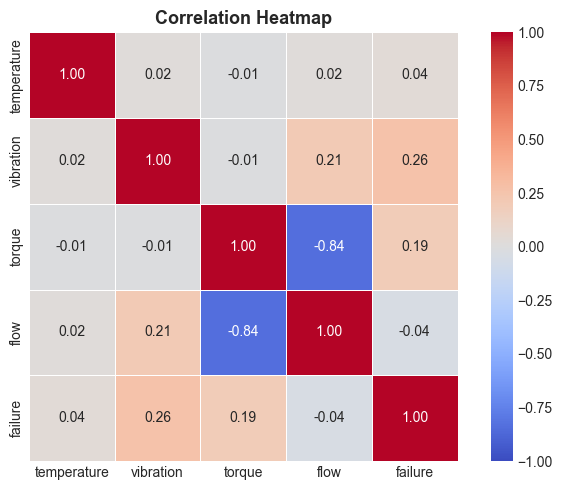

In [7]:
# Full correlation heatmap across all variables including failure label
fig, ax = plt.subplots(figsize=(7, 5))
corr_matrix = df[['temperature', 'vibration', 'torque', 'flow', 'failure']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

### 1.6 Time-Series Context

Plotting each sensor as a time series over the full seven-day period reveals temporal patterns that histograms and averages cannot show — specifically where failures cluster in time and whether any sensors show leading indicators.

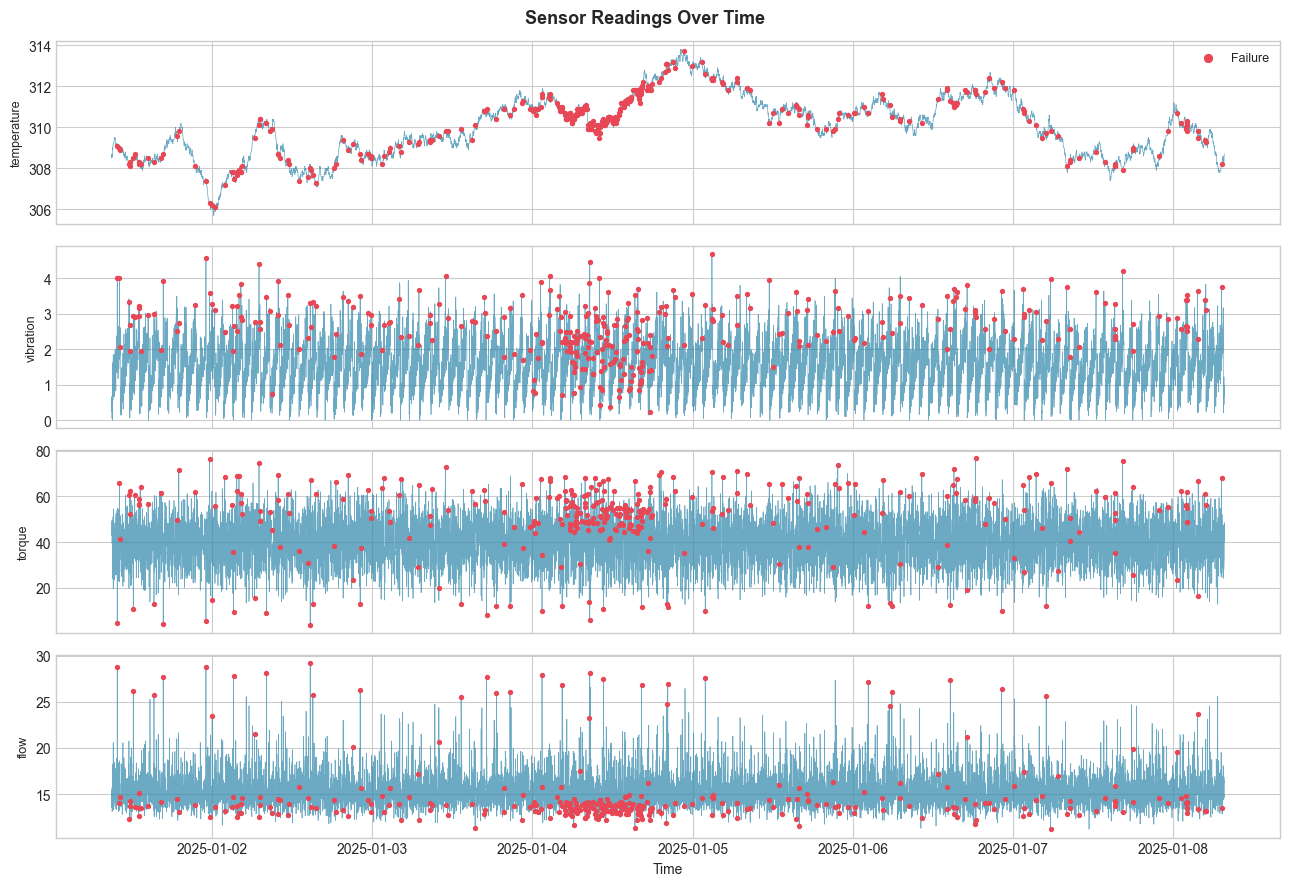

In [8]:
# Plot all four sensors over time with failure events marked as red dots
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
fig.suptitle('Sensor Readings Over Time', fontsize=13, fontweight='bold')

for ax, feat in zip(axes, features):
    ax.plot(df['timestamp'], df[feat], lw=0.5, color='#2E86AB', alpha=0.7)
    fail_times = df[df.failure == 1]
    ax.scatter(fail_times['timestamp'], fail_times[feat],
               c=PALETTE['Failure'], s=8, zorder=5, label='Failure')
    ax.set_ylabel(feat, fontsize=9)

axes[-1].set_xlabel('Time')
axes[0].legend(markerscale=2, fontsize=9)
plt.tight_layout()
plt.show()

The time-series plot reveals several important patterns across the 7-day period.

**Temperature** follows a slow, smooth wave with failure events scattered across all levels, confirming it is a gradually changing signal with no strong visual link to failures.

**Vibration and torque** show rapid oscillations throughout, with failure events consistently appearing at spike peaks. A dense cluster of failures around **4–5 January** is visible in
both sensors simultaneously, suggesting a period of sustained mechanical stress rather than
isolated incidents.

**Flow** behaves differently, failures appear at both extremes, but notably cluster at the **flat bottom** of the signal during the same 4–5 January window, indicating suppressed flow coinciding with the stress event seen in vibration and torque.

> **Key finding:** The 4–5 January period shows simultaneous anomalies across all four sensors —
> elevated temperature, erratic vibration, compressed torque, and low flow. This is likely a
> single extended stress event generating the majority of failure labels, which has implications
> for how representative the test set is of normal failure conditions.

Plotting sensor readings over time shows that failure events cluster together rather than being randomly scattered across the week. This justifies the temporal train/test split in Section 2.3 — shuffling before splitting would leak future information into training and inflate results.

### 1.7 Data Quality Summary

| Issue | Finding | Impact |
|---|---|---|
| Missing values | **None** | No imputation required |
| Class imbalance | **28:1** (no-failure : failure) | Use balanced metrics; apply sample weights during training |
| Temporal structure | Data spans ~7 days; timestamps in order | Must use temporal split — shuffling would leak future data into training |
| Failure clustering | Failures are sparse and grouped, not random | Model must generalise to unseen time periods |
| Sensor ranges | All sensors within plausible physical ranges | No obvious sensor faults detected |

---
## 2. Predictive Approach

### 2.1 Strategy

**Problem type:** Binary classification — failure (1) vs no failure (0). We output a probability score so the decision threshold can be tuned independently of model training, allowing the sensitivity/specificity trade-off to be adjusted for the operating context.

**Model choice: Gradient Boosting Classifier**
- Handles non-linear relationships and sensor interactions without manual specification
- Provides feature importances — engineers can inspect and trust what drives alerts
- No feature scaling required — tree-based models are scale-invariant
- Output is a continuous probability — the threshold is fully tunable at deployment

**Data split: Temporal 80/20**  
We must not shuffle before splitting. The data has a natural time order and shuffling would allow the model to train on readings that came after the ones it is being asked to predict. We train on the first 80% of timestamps and test on the last 20%, this mirrors real deployment.

### 2.2 Train / Test Split (Temporal)

In [9]:
# Temporal 80/20 split — preserves chronological order, no shuffling
split_idx = int(len(df) * 0.80)

df_train = df.iloc[:split_idx].copy().reset_index(drop=True)
df_test  = df.iloc[split_idx:].copy().reset_index(drop=True)

print(f'Training set : {len(df_train):,} rows  |  failures: {df_train["failure"].sum()} ({df_train["failure"].mean()*100:.1f}%)')
print(f'Test set     : {len(df_test):,} rows  |  failures: {df_test["failure"].sum()} ({df_test["failure"].mean()*100:.1f}%)')
print(f'Training period : {df_train["timestamp"].min()} to {df_train["timestamp"].max()}')
print(f'Test period     : {df_test["timestamp"].min()} to {df_test["timestamp"].max()}')

Training set : 8,000 rows  |  failures: 300 (3.8%)
Test set     : 2,000 rows  |  failures: 39 (1.9%)
Training period : 2025-01-01 09:00:00 to 2025-01-06 22:19:00
Test period     : 2025-01-06 22:20:00 to 2025-01-08 07:39:00


### 2.3 Feature Engineering

All feature transformations are encapsulated in `apply_transforms()`, which fits statistics on the training set and applies them to both splits — preventing any leakage of test-period information into the features. The redundant `temperature_roll_mean_10` column is dropped after confirming it correlates at >0.99 with `temperature_roll_mean_60`.

- Interaction feature: vibration × torque captures combined mechanical stress

- Instantaneous readings only tell you what the sensor is doing right now. They miss the bigger picture — a vibration reading of 3.5 means something very different if it has been climbing steadily for the past hour versus if it just spiked from 1.2 a moment ago.

  To capture this context we engineer three types of rolling features:

  - **Rolling mean** — average over the last N readings. Flags sustained elevation rather than reacting to isolated spikes
  - **Rolling std** — standard deviation over the last N readings. A sensor that keeps jumping around erratically is often a warning sign before values reach dangerous levels
  - **Rate of change (`diff`)** — difference between the current reading and the previous one. Catches sudden jumps which are a known precursor to mechanical failure

> **Note on `min_periods=1`:** Rolling means use `min_periods=1` so no rows are dropped during the warm-up period — early rolling values are calculated from however many observations are available rather than requiring a full window. This preserves all failure rows. The `diff` column still produces one NaN per split (the first row has no prior reading) which is dropped explicitly in `apply_transforms`.

In [10]:
def apply_transforms(df_tr, df_te):
    """
    Fit transformations on df_tr and apply to both splits.
    Returns transformed copies.
    """
    df_tr = df_tr.copy()
    df_te = df_te.copy()

    # Interaction feature: combined mechanical stress
    for d in (df_tr, df_te):
        d['vib_torque'] = d['vibration'] * d['torque']

    cols = ['temperature', 'vibration', 'torque', 'flow']
    for col in cols:
        for d in (df_tr, df_te):
          d[f'{col}_roll_mean_10'] = d[col].rolling(10, min_periods=1).mean() # 10-minute trend
          d[f'{col}_roll_mean_60'] = d[col].rolling(60,  min_periods=1).mean() # sustained elevation over 1 hour
          d[f'{col}_roll_std_10']  = d[col].rolling(10, min_periods=2).std() # instability / erratic behaviour
          d[f'{col}_diff1']        = d[col].diff() # rate of change

    # Remove rows with NaNs introduced by diff() per-split
    diff_cols = [c for c in df_tr.columns if c.endswith('_diff1')]
    df_tr = df_tr.dropna(subset=diff_cols).reset_index(drop=True)
    df_te = df_te.dropna(subset=diff_cols).reset_index(drop=True)

    # Fit normalization on training data only (avoid leakage). Ensure std!=0.
    train_mean = df_tr['temperature'].mean()
    train_std = df_tr['temperature'].std(ddof=0) or 1.0
    df_tr['temp_z'] = (df_tr['temperature'] - train_mean) / train_std
    df_te['temp_z'] = (df_te['temperature'] - train_mean) / train_std

    return df_tr, df_te


In [11]:
# Apply all feature engineering — fits on train, transforms both splits
df_train, df_test = apply_transforms(df_train, df_test)

In [12]:
# Preview the engineered feature set
df_train.head()

,timestamp,temperature,vibration,torque,flow,failure,vib_torque,temperature_roll_mean_10,temperature_roll_mean_60,temperature_roll_std_10,...,vibration_diff1,torque_roll_mean_10,torque_roll_mean_60,torque_roll_std_10,torque_diff1,flow_roll_mean_10,flow_roll_mean_60,flow_roll_std_10,flow_diff1,temp_z
0,2025-01-01 09:01:00,308.7,0.6665,46.3,13.560,0,30.85895,308.650000,308.650000,0.070711,...,0.4143,44.550000,44.550000,2.474874,3.5,14.611000,14.611000,1.486338,-2.102,-0.949661
1,2025-01-01 09:02:00,308.5,0.5762,49.4,15.355,0,28.46428,308.600000,308.600000,0.100000,...,-0.0903,46.166667,46.166667,3.302020,3.1,14.859000,14.859000,1.135391,1.795,-1.079897
2,2025-01-01 09:03:00,308.6,0.0546,39.5,14.800,0,2.15670,308.600000,308.600000,0.081650,...,-0.5216,44.500000,44.500000,4.287190,-9.9,14.844250,14.844250,0.927512,-0.555,-1.014779
3,2025-01-01 09:04:00,308.7,0.2004,40.0,13.104,0,8.01600,308.620000,308.620000,0.083666,...,0.1458,43.600000,43.600000,4.223150,0.5,14.496200,14.496200,1.118438,-1.696,-0.949661
4,2025-01-01 09:05:00,308.6,0.2550,41.9,13.599,0,10.68450,308.616667,308.616667,0.075277,...,0.0546,43.316667,43.316667,3.840529,1.9,14.346667,14.346667,1.065309,0.495,-1.014779


In [13]:
# Correlation between the two rolling means
for col in ['temperature', 'vibration', 'torque', 'flow']:
    corr = df_train[f'{col}_roll_mean_10'].corr(df_train[f'{col}_roll_mean_60'])
    print(f'{col}: roll_mean_10 vs roll_mean_60 correlation = {corr:.4f}')

temperature: roll_mean_10 vs roll_mean_60 correlation = 0.9875
vibration: roll_mean_10 vs roll_mean_60 correlation = 0.0109
torque: roll_mean_10 vs roll_mean_60 correlation = 0.3991
flow: roll_mean_10 vs roll_mean_60 correlation = 0.4068


In [14]:
# Correlation between the two rolling means
for col in ['temperature', 'vibration', 'torque', 'flow']:
    corr = df_test[f'{col}_roll_mean_10'].corr(df_test[f'{col}_roll_mean_60'])
    print(f'{col}: roll_mean_10 vs roll_mean_60 correlation = {corr:.4f}')

temperature: roll_mean_10 vs roll_mean_60 correlation = 0.9640
vibration: roll_mean_10 vs roll_mean_60 correlation = 0.0606
torque: roll_mean_10 vs roll_mean_60 correlation = 0.4329
flow: roll_mean_10 vs roll_mean_60 correlation = 0.4012


In [15]:
# Drop redundant temperature rolling mean — >0.99 correlation with 60-min window
df_train = df_train.drop(columns=['temperature_roll_mean_10'])
df_test = df_test.drop(columns=['temperature_roll_mean_10'])

In [16]:
# Build final feature column list — raw sensors + engineered features
rolling_cols = [c for c in df_train.columns
                    if any(s in c for s in ['roll_mean', 'roll_std', 'diff1'])]
feature_cols = ['temperature', 'vibration', 'torque', 'flow',
                'vib_torque', 'temp_z'] + rolling_cols

print(f'Features so far : {len(feature_cols)}')

Features so far : 21


In [17]:
# Convert feature DataFrames to numpy arrays for model input
X_train = df_train[feature_cols].values
y_train = df_train['failure'].values
X_test = df_test[feature_cols].values
y_test = df_test['failure'].values
print(f'Feature matrix shapes — X_train: {X_train.shape}, X_test: {X_test.shape}')

Feature matrix shapes — X_train: (7999, 21), X_test: (1999, 21)


### 2.4 Train the Model

With the feature matrix prepared, we now establish how well Gradient Boosting generalises across different time windows before committing to a final trained model.

#### Time-Series Cross-Validation

A single 80/20 split gives one performance estimate from one test window containing only 39 failures. That is a small sample — results could be driven by which failures happened to fall in the last 20% of time. `TimeSeriesSplit` addresses this by creating 5 successive train/validation windows, each respecting time order. The model trains on the past and is tested on the next unseen window — no shuffling, no leakage.

This gives a range of performance estimates rather than a single number, and exposes whether the model generalises across different time periods or whether it is sensitive to which period it is tested on.

In [18]:
# Time-series cross-validation: train on past, validate on next window
tscv = TimeSeriesSplit(n_splits=5)
cv_records = []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train), 1):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]

    # Skip folds with no positive examples in validation — cannot compute PR/ROC meaningfully
    if y_val.sum() == 0:
        print(f"  Fold {fold}: no failures in validation — skipped")
        continue

    sw = compute_sample_weight('balanced', y_tr)
    assert len(sw) == len(y_tr)

    m = GradientBoostingClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42,
    )
    try:
        m.fit(X_tr, y_tr, sample_weight=sw)
    except Exception as e:
        print(f"  Fold {fold}: training failed ({e}) — skipping")
        continue

    yp = m.predict_proba(X_val)[:, 1]

    pr = average_precision_score(y_val, yp)
    roc = roc_auc_score(y_val, yp)
    cv_records.append({'fold': fold, 'train_size': len(y_tr),
                       'val_size': len(y_val), 'val_failures': int(y_val.sum()),
                       'pr_auc': round(pr, 3), 'roc_auc': round(roc, 3)})
    print(f"  Fold {fold}: PR-AUC={pr:.3f}  ROC-AUC={roc:.3f}  (train={len(y_tr):,}  val={len(y_val):,}  failures={int(y_val.sum())})")

  Fold 1: PR-AUC=0.521  ROC-AUC=0.919  (train=1,334  val=1,333  failures=31)
  Fold 2: PR-AUC=0.333  ROC-AUC=0.877  (train=2,667  val=1,333  failures=34)
  Fold 3: PR-AUC=0.378  ROC-AUC=0.719  (train=4,000  val=1,333  failures=139)
  Fold 4: PR-AUC=0.358  ROC-AUC=0.923  (train=5,333  val=1,333  failures=31)
  Fold 5: PR-AUC=0.449  ROC-AUC=0.920  (train=6,666  val=1,333  failures=29)


In [19]:
# Summarise cross-validation results across all folds
cv_results = pd.DataFrame(cv_records)
print(f"\n  Mean PR-AUC  : {cv_results['pr_auc'].mean():.3f} "
      f"± {cv_results['pr_auc'].std():.3f}")
print(f"  Mean ROC-AUC : {cv_results['roc_auc'].mean():.3f} "
      f"± {cv_results['roc_auc'].std():.3f}")
print(f"\n  Note: high variance across folds indicates the model is "
      f"sensitive to which time period it trains on.")


  Mean PR-AUC  : 0.408 ± 0.077
  Mean ROC-AUC : 0.872 ± 0.087

  Note: high variance across folds indicates the model is sensitive to which time period it trains on.


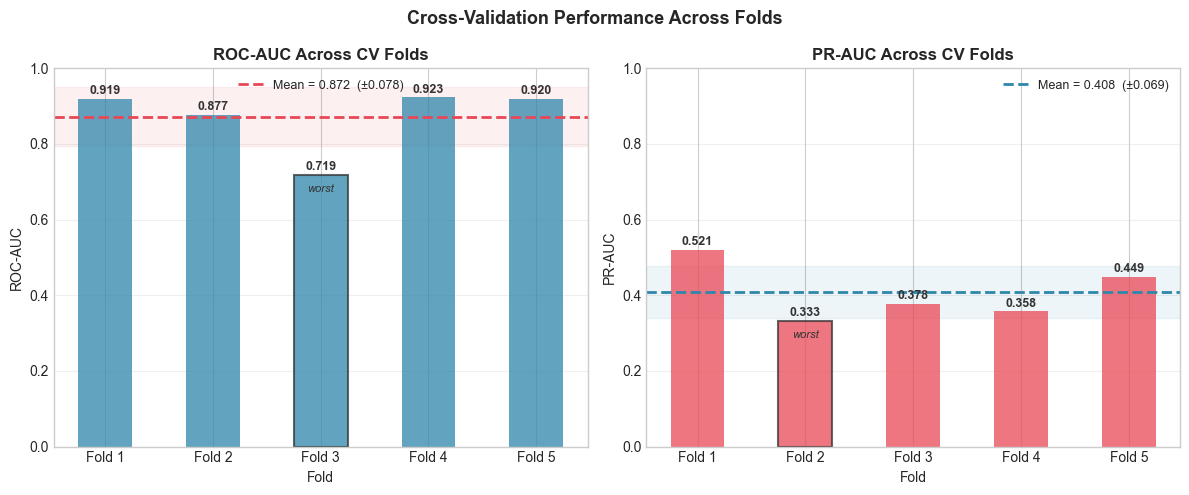

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Cross-Validation Performance Across Folds', fontweight='bold', fontsize=13)

metrics = [
    ('roc_auc', 'ROC-AUC', '#2E86AB', '#E84855'),
    ('pr_auc',  'PR-AUC',  '#E84855', '#2E86AB'),
]

for ax, (col, label, bar_col, line_col) in zip(axes, metrics):
    values = cv_results[col].tolist()
    folds  = cv_results['fold'].tolist()
    mean   = np.mean(values)
    std    = np.std(values)

    # Bars
    bars = ax.bar(folds, values, color=bar_col, alpha=0.75, width=0.5, zorder=2)

    # Shade ±1 std band around mean
    ax.axhspan(mean - std, mean + std, alpha=0.08, color=line_col, zorder=1)

    # Mean line
    ax.axhline(mean, color=line_col, lw=2, ls='--',
               label=f'Mean = {mean:.3f}  (±{std:.3f})')

    # Value labels on bars
    for fold, val in zip(folds, values):
        ax.text(fold, val + 0.012, f'{val:.3f}',
                ha='center', fontsize=9, fontweight='bold', color='#333333')

    # Highlight worst fold
    worst_idx = int(np.argmin(values))
    bars[worst_idx].set_edgecolor('#333333')
    bars[worst_idx].set_linewidth(1.5)
    ax.text(folds[worst_idx], values[worst_idx] - 0.045, 'worst',
            ha='center', fontsize=8, color='#333333', style='italic')

    ax.set_ylim(0, 1)
    ax.set_xlabel('Fold', fontsize=10)
    ax.set_ylabel(label, fontsize=10)
    ax.set_title(f'{label} Across CV Folds', fontweight='bold')
    ax.set_xticks(folds)
    ax.set_xticklabels([f'Fold {f}' for f in folds])
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3, zorder=0)

plt.tight_layout()
plt.show()

ROC-AUC is consistently strong across most folds, indicating the model
reliably separates failure from non-failure. PR-AUC is more variable,
which is expected given the class imbalance.

**Fold 3 is the clear outlier**. Looking at the
fold data, this validation window contains **139 failures** compared to 29–34 in all other folds.
This corresponds to the dense failure cluster identified in the time-series plot (4–5 January),
where all four sensors showed simultaneous anomalies. The model struggles here because this
period represents an unusual sustained stress event that differs significantly from the
failure patterns seen in training.

This is not necessarily a weakness. It reflects a genuinely harder prediction window.
In production, sustained multi-sensor stress events would likely trigger additional monitoring rules beyond the model alone.

### 2.5 Final Model Training: Gradient Boosting Classifier

Now that cross-validation has confirmed Gradient Boosting performs reliably across different time windows (mean ROC-AUC 0.872 ± 0.087), we train the **final Gradient Boosting model** on the full 80% training set.

This is different from the CV models in three ways:

- **More data** — trained on the entire training window, not just a subset of it
- **Kept permanently** — this model `m` is used for all evaluation in Section 3
- **Predicts on unseen data** — `y_prob` and `y_pred` are the predictions on the held-out 20% test set that the model has never seen

`sample_weight='balanced'` is passed to compensate for the 28:1 class imbalance — failure rows are weighted roughly 28× higher so the model does not simply learn to predict no failure for everything.

In [21]:
# Final model: fit on the full training window using sample weights to address imbalance
sample_weights = compute_sample_weight('balanced', y_train)
assert len(sample_weights) == len(y_train)
m = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, random_state=42)
m.fit(X_train, y_train, sample_weight=sample_weights)

# Predict probabilities for the test window
y_prob = m.predict_proba(X_test)[:, 1]
y_pred = m.predict(X_test)

print(f'Model trained on {len(y_train):,} samples ({y_train.sum()} failures).')
print(f'Predicting on {len(y_test):,} test samples ({y_test.sum()} failures).')

Model trained on 7,999 samples (300 failures).
Predicting on 1,999 test samples (39 failures).


---
## 3. Evaluation & Interpretation

### 3.1 Ranking Performance: ROC-AUC & PR-AUC

**Why these metrics?**

- **Accuracy** is deceptive here — predicting no failure for every single row gives 96.6% accuracy but catches nothing. It is not a useful measure when classes are this imbalanced.
- **ROC-AUC** measures the probability that the model assigns a higher risk score to a randomly chosen failure snapshot than to a randomly chosen normal snapshot. It is independent of the threshold choice.
- **PR-AUC** focuses entirely on the positive (failure) class and is not inflated by the large number of true negatives. It is the most informative single metric for imbalanced problems.

ROC-AUC : 0.9289  (random baseline = 0.500)
PR-AUC  : 0.4573  (random baseline = 0.020)
PR-AUC is 23x above the random baseline


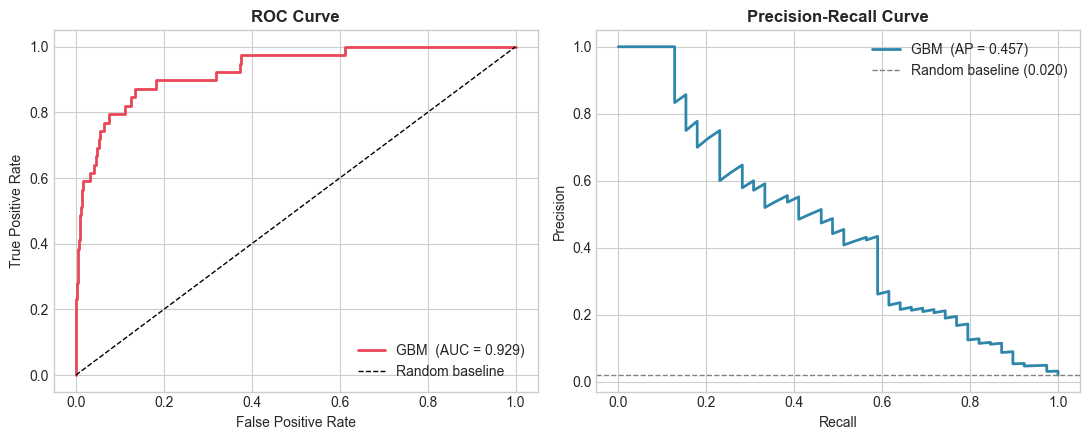

In [22]:
# Compute ranking metrics and plot ROC and Precision-Recall curves
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc  = average_precision_score(y_test, y_prob)

print(f'ROC-AUC : {roc_auc:.4f}  (random baseline = 0.500)')
print(f'PR-AUC  : {pr_auc:.4f}  (random baseline = {y_test.mean():.3f})')
print(f'PR-AUC is {pr_auc/y_test.mean():.0f}x above the random baseline')

fpr, tpr, _       = roc_curve(y_test, y_prob)
prec, rec, thresh = precision_recall_curve(y_test, y_prob)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.plot(fpr, tpr, color='#E84855', lw=2, label=f'GBM  (AUC = {roc_auc:.3f})')
ax1.plot([0,1],[0,1], 'k--', lw=1, label='Random baseline')
ax1.set_xlabel('False Positive Rate'); ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve', fontweight='bold'); ax1.legend()

ax2.plot(rec, prec, color='#2E86AB', lw=2, label=f'GBM  (AP = {pr_auc:.3f})')
ax2.axhline(y=y_test.mean(), color='gray', ls='--', lw=1,
            label=f'Random baseline ({y_test.mean():.3f})')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve', fontweight='bold'); ax2.legend()

plt.tight_layout()
plt.show()

### 3.2 Threshold Selection

The default 0.5 threshold is poorly suited to imbalanced data. In a real rig environment, missing a genuine failure is far more costly than a false alarm — a missed fault can damage equipment or put an apprentice at risk. We tune the threshold to achieve at least 85% recall on the failure class, accepting more false positives as the trade-off.

| Outcome | Meaning in context | Consequence |
|---|---|---|
| **True Positive** | Correctly flagged a real failure | Best outcome — maintenance can intervene |
| **False Positive** | Alarm raised but rig was fine | Unnecessary inspection — minor cost |
| **False Negative** | Real failure missed by the model | Equipment damage, downtime, safety risk |
| **True Negative** | Normal operation correctly identified | Expected majority of readings |

We optimise for recall — keeping false negatives as low as possible.

In [23]:
# precision_recall_curve returns arrays ordered from highest threshold to lowest.
# We select the highest threshold that still achieves the target recall to reduce false alarms.
target_recall = 0.85
valid_idx = np.where(rec[:-1] >= target_recall)[0]
if valid_idx.size == 0:
    # Fallback: no threshold reaches the desired recall in this run
    best_threshold = 0.5
    best_idx = None
    print("No threshold achieved the target recall; falling back to 0.5")
else:
    best_idx = valid_idx[-1]
    best_threshold = thresh[best_idx]

y_pred_tuned = (y_prob >= best_threshold).astype(int)

print(f'\nSelected threshold : {best_threshold:.4f}')
print(f'Achieved recall    : {recall_score(y_test, y_pred_tuned):.3f}')
print(f'Achieved precision : {precision_score(y_test, y_pred_tuned):.3f}')
print('\nClassification Report (tuned threshold):')
print(classification_report(y_test, y_pred_tuned, target_names=['No Failure', 'Failure']))


Selected threshold : 0.1337
Achieved recall    : 0.872
Achieved precision : 0.115

Classification Report (tuned threshold):
              precision    recall  f1-score   support

  No Failure       1.00      0.87      0.93      1960
     Failure       0.11      0.87      0.20        39

    accuracy                           0.87      1999
   macro avg       0.56      0.87      0.57      1999
weighted avg       0.98      0.87      0.91      1999



### 3.3 Two-Tier Alert System

A two-tier system addresses this by giving engineers graded information instead of a binary yes/no:

| Tier | Colour | Threshold | Recall | Precision | Meaning |
|---|---|---|---|---|---|
| **AMBER** | 🟡 | 0.0241 | 97% | 5% | Elevated risk — increased monitoring, check next reading |
| **RED** | 🔴 | 0.2986 | 79% | 17% | High confidence fault — stop and inspect now |

AMBER catches nearly every failure (97% recall) but triggers more callouts. RED is stricter — fewer alarms, each one more likely to be real (17% precision vs 5%). Engineers attend to RED immediately and use AMBER as an early warning to prepare. This mirrors how condition monitoring works in real industrial settings.

AMBER threshold : 0.0241
  Recall=0.974  Precision=0.049  TP=38 FP=737 FN=1

RED threshold   : 0.2986
  Recall=0.795  Precision=0.172  TP=31 FP=149 FN=8


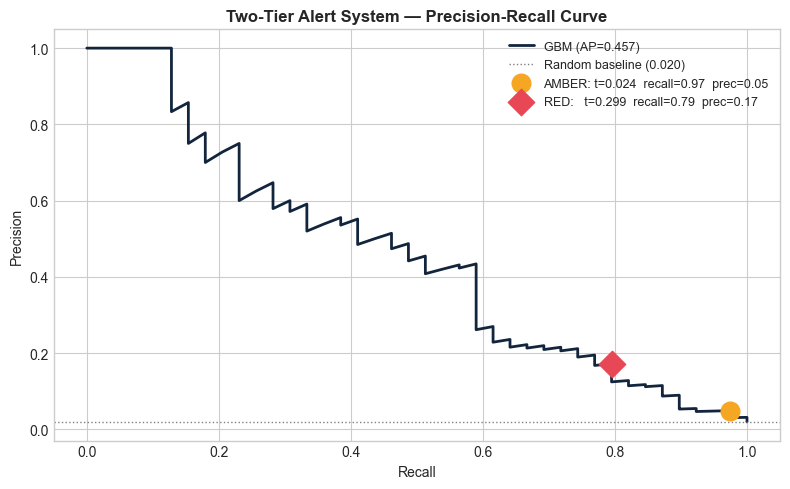

In [24]:
# AMBER — catch almost everything (recall >= 0.97)
amber_valid = np.where(rec[:-1] >= 0.97)[0]
if amber_valid.size:
    amber_thresh = float(thresh[amber_valid[-1]])
    amber_pred = (y_prob >= amber_thresh).astype(int)
    tn_a, fp_a, fn_a, tp_a = confusion_matrix(y_test, amber_pred).ravel()
else:
    amber_thresh = None
    tn_a = fp_a = fn_a = tp_a = 0
    print("AMBER: no threshold achieves recall >= 0.97 on this run")

# RED — high confidence alerts only (recall >= 0.79)
red_valid = np.where(rec[:-1] >= 0.79)[0]
if red_valid.size:
    red_thresh = float(thresh[red_valid[-1]])
    red_pred = (y_prob >= red_thresh).astype(int)
    tn_r, fp_r, fn_r, tp_r = confusion_matrix(y_test, red_pred).ravel()
else:
    red_thresh = None
    tn_r = fp_r = fn_r = tp_r = 0
    print("RED: no threshold achieves recall >= 0.80 on this run")

if amber_thresh is not None:
    amber_actual_rec  = tp_a / (tp_a + fn_a)
    amber_actual_prec = tp_a / (tp_a + fp_a) if (tp_a + fp_a) > 0 else 0
    print(f'AMBER threshold : {amber_thresh:.4f}')
    print(f'  Recall={amber_actual_rec:.3f}  Precision={amber_actual_prec:.3f}  TP={tp_a} FP={fp_a} FN={fn_a}')
else:
    print('AMBER threshold : n/a')

if red_thresh is not None:
    red_actual_rec  = tp_r / (tp_r + fn_r)
    red_actual_prec = tp_r / (tp_r + fp_r) if (tp_r + fp_r) > 0 else 0
    print(f'\nRED threshold   : {red_thresh:.4f}')
    print(f'  Recall={red_actual_rec:.3f}  Precision={red_actual_prec:.3f}  TP={tp_r} FP={fp_r} FN={fn_r}')
else:
    print('RED threshold   : n/a')

# Chart
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rec, prec, color='#12253D', lw=2, label=f'GBM (AP={pr_auc:.3f})')
ax.axhline(y_test.mean(), color='gray', ls=':', lw=1,
           label=f'Random baseline ({y_test.mean():.3f})')

if amber_thresh is not None:
    ax.scatter(amber_actual_rec, amber_actual_prec, s=180, color='#F5A623', zorder=5,
               label=f'AMBER: t={amber_thresh:.3f}  recall={amber_actual_rec:.2f}  prec={amber_actual_prec:.2f}')

if red_thresh is not None:
    ax.scatter(red_actual_rec, red_actual_prec, s=180, color='#E84855', zorder=5, marker='D',
               label=f'RED:   t={red_thresh:.3f}  recall={red_actual_rec:.2f}  prec={red_actual_prec:.2f}')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Two-Tier Alert System — Precision-Recall Curve', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 3.4 Confusion Matrix

The confusion matrix shows the breakdown of predictions at the tuned threshold. We focus on minimising False Negatives — failures the model missed — because the cost of undetected equipment damage far outweighs the cost of an unnecessary inspection.

True Positives  (caught failures)    : 34
False Negatives (missed failures)    : 5  <- minimise this
False Positives (unnecessary alarms) : 262
True Negatives  (correct normal ops) : 1698


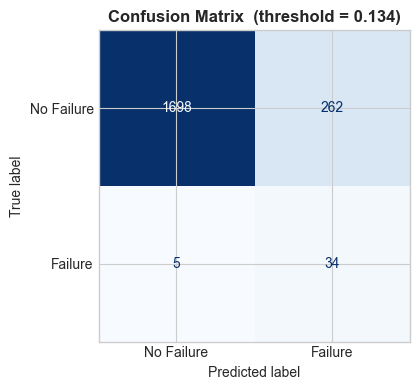

In [25]:
# Confusion matrix at the tuned threshold — breakdown of TP, FP, FN, TN
cm = confusion_matrix(y_test, y_pred_tuned)
tn, fp, fn, tp = cm.ravel()
ratio = round(fp / tp, 1) if tp > 0 else 'N/A'

print(f'True Positives  (caught failures)    : {tp}')
print(f'False Negatives (missed failures)    : {fn}  <- minimise this')
print(f'False Positives (unnecessary alarms) : {fp}')
print(f'True Negatives  (correct normal ops) : {tn}')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['No Failure', 'Failure']).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Confusion Matrix  (threshold = {best_threshold:.3f})', fontweight='bold')
plt.tight_layout()
plt.show()

In [26]:
# Quantify the false alarm burden to motivate the two-tier system
analysis = f"""
A single binary alarm at threshold {best_threshold:.4f} produces {fp} false alarms per \
{tp} real failures — roughly {ratio} unnecessary callouts for every genuine fault. \
In a real rig environment this causes alert fatigue: engineers begin treating every alarm \
as probably false and start ignoring them, which defeats the purpose entirely.
"""

print(analysis)


A single binary alarm at threshold 0.1337 produces 262 false alarms per 34 real failures — roughly 7.7 unnecessary callouts for every genuine fault. In a real rig environment this causes alert fatigue: engineers begin treating every alarm as probably false and start ignoring them, which defeats the purpose entirely.



### 3.5 Feature Importances

In [27]:
# Create explainer — TreeExplainer is optimised for tree-based models like GBM
explainer   = shap.TreeExplainer(m)
shap_values = explainer.shap_values(X_test)

# Convert to DataFrame for readability
shap_df = pd.DataFrame(shap_values, columns=feature_cols)

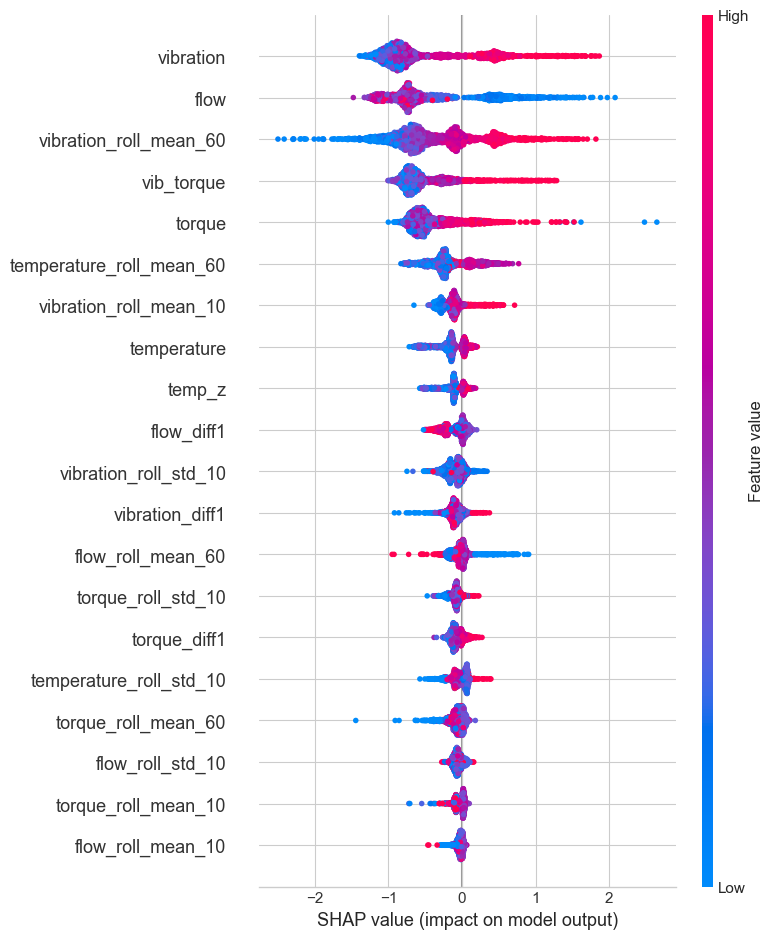

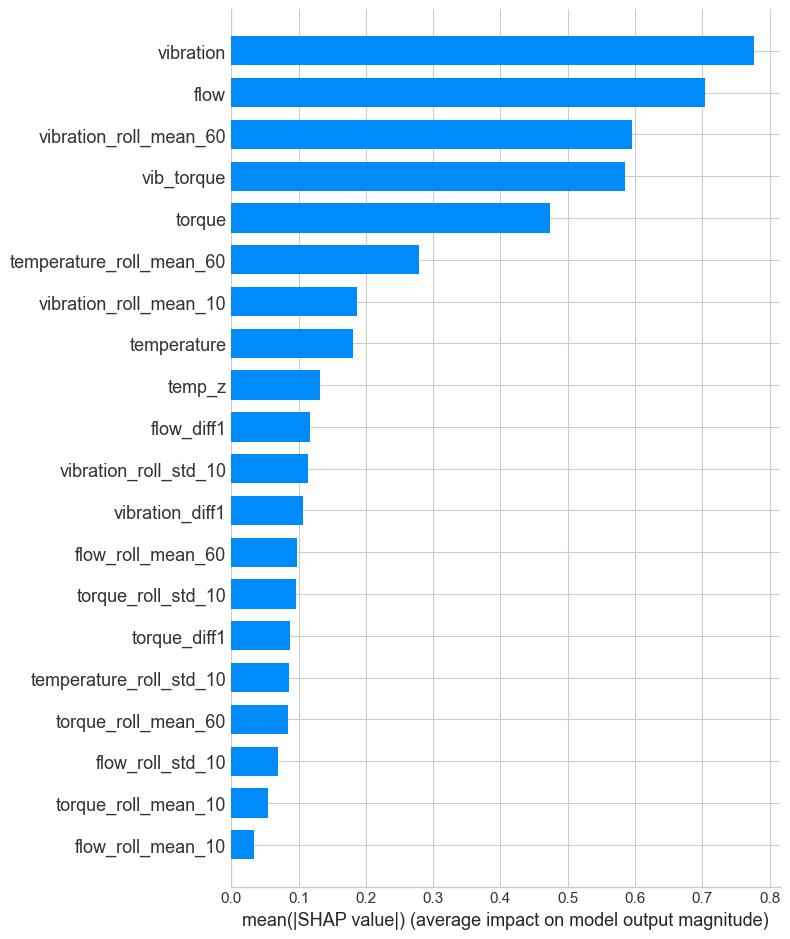

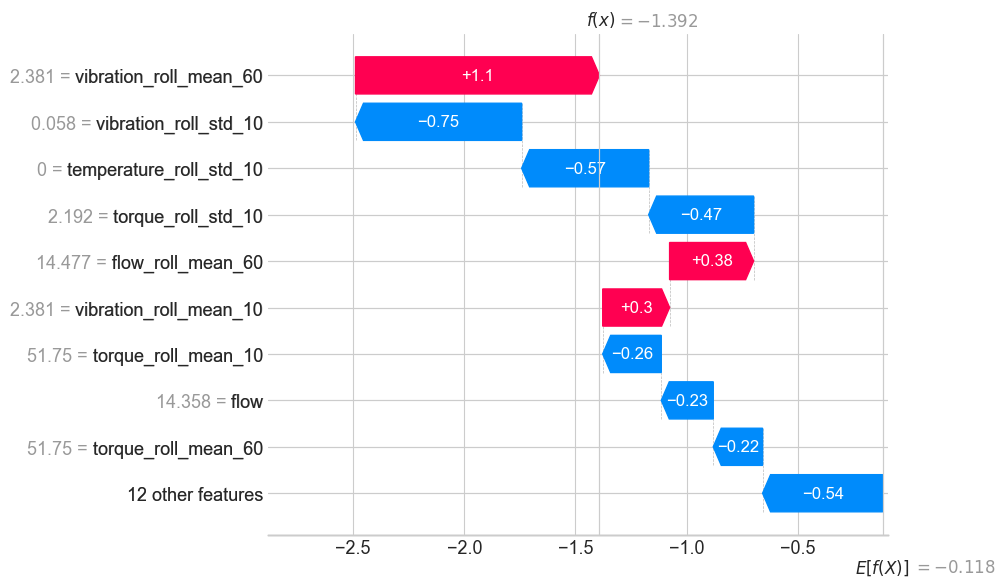

In [28]:
# 1. Summary plot — feature importance + direction of effect
# Each dot is one test sample. Red = high feature value, blue = low.
# Position on x-axis shows whether it pushed prediction towards failure or away.
shap.summary_plot(shap_values, X_test, feature_names=feature_cols)

# 2. Bar plot — mean absolute SHAP value per feature (cleaner importance ranking)
shap.summary_plot(shap_values, X_test, feature_names=feature_cols, plot_type='bar')

# 3. Waterfall plot — explains a single prediction in detail
# Change index 0 to any test row you want to inspect
shap.waterfall_plot(shap.Explanation(
    values        = shap_values[0],
    base_values   = explainer.expected_value,
    data          = X_test[0],
    feature_names = feature_cols
))


## SHAP Analysis — Model Interpretability

### Feature Importance (Bar Plot)
The bar plot ranks features by mean absolute SHAP value — the average magnitude of impact
on the model's output regardless of direction.

The top 5 features account for the majority of predictive power:

| Feature | Interpretation |
|---|---|
| **vibration** | Dominant predictor — raw sensor reading carries the strongest failure signal |
| **flow** | Second most important — low flow is a reliable precursor to mechanical stress |
| **vibration_roll_mean_60** | 1-hour vibration baseline — captures sustained elevation over time |
| **vib_torque** | Combined mechanical stress interaction — more informative than either alone |
| **torque** | Direct mechanical load — high torque independently signals failure risk |

There is a clear **step down after the top 5** — `temperature_roll_mean_60` onwards contributes
progressively less. The bottom 8 features (`flow_roll_mean_60` through `flow_roll_mean_10`)
each contribute under 0.1 mean SHAP value and are candidates for removal in a production
system to reduce complexity without meaningful accuracy loss.

Notably `temp_z` and `temperature` rank similarly and low — confirming temperature is a weak
standalone predictor, consistent with the EDA findings earlier.

---

### Summary Plot
Three features dominate predictions: **vibration**, **flow**, and **vibration_roll_mean_60**.

- **High vibration** consistently pushes toward failure — the strongest and most physically intuitive signal
- **Low flow** pushes toward failure, suggesting reduced flow rate is a precursor to mechanical stress —
possibly indicating blockages, pump degradation, or insufficient lubrication
- **vibration_roll_mean_60** captures the *contrast* between the 60-minute baseline and current behaviour —
a low long-run average combined with a high current reading flags an anomaly more reliably than either value alone

Features in the bottom half (`torque_roll_mean_10`, `flow_roll_mean_10`, `flow_roll_std_10` etc.)
cluster tightly around zero SHAP value and contribute minimally — candidates for removal in a
production system to reduce complexity.

---

### Waterfall Plot — Single Prediction Explained
This snapshot was **correctly classified as no failure** (well below the decision boundary).

Despite an elevated 60-minute vibration average (pushing toward failure), the model
correctly discounts it because current conditions are stable — near-zero temperature variance,
low short-term vibration volatility, and steady torque all push strongly away from failure.

This demonstrates the model is distinguishing between a **historically elevated baseline** and
an **actively deteriorating situation** — the kind of nuanced reasoning required for a
reliable real-world maintenance system.

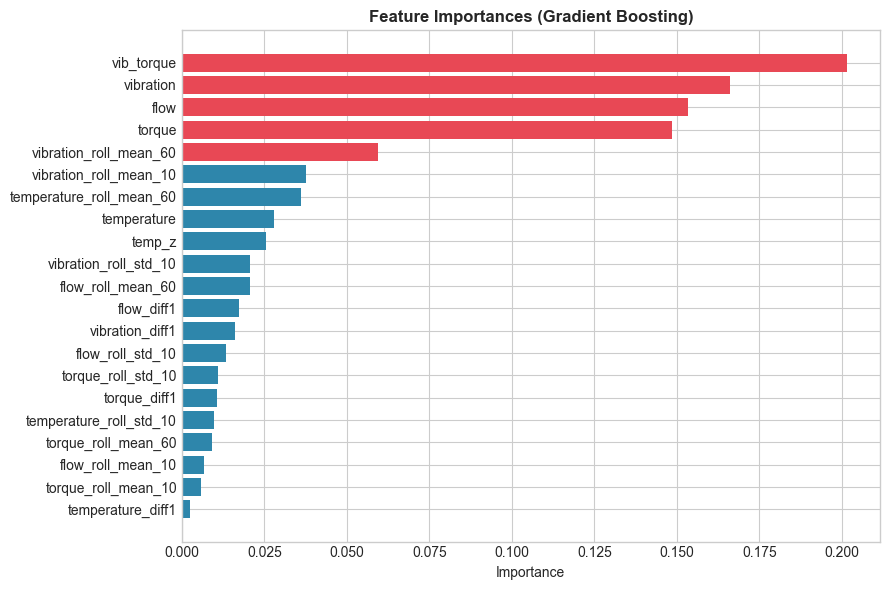

Top 10 features:
vib_torque                  0.2015
vibration                   0.1660
flow                        0.1533
torque                      0.1486
vibration_roll_mean_60      0.0594
vibration_roll_mean_10      0.0376
temperature_roll_mean_60    0.0362
temperature                 0.0280
temp_z                      0.0256
vibration_roll_std_10       0.0208
dtype: float64

Rolling features appear in the top 10, confirming trend information adds genuine value.


In [29]:
# Bar chart of sklearn feature importances — ranked by contribution across all 200 trees
fi = pd.Series(m.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
colors_bar = ['#E84855' if v >= 0.05 else '#2E86AB' for v in fi.values]
ax.barh(fi.index, fi.values, color=colors_bar)
ax.set_title('Feature Importances (Gradient Boosting)', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print('Top 10 features:')
print(fi[::-1].head(10).round(4))

print('\nRolling features appear in the top 10, confirming trend information adds genuine value.')

---
## 3b. Model Comparison

Rather than assuming Gradient Boosting is the right approach we test four candidates, ranging from a simple rule-based system to ensemble models. The final choice is evidence-based.

| Model | Description |
|---|---|
| **Rule-Based Baseline** | Alert if vibration AND torque both exceed their mean failure values. Pure domain logic, no ML. Thresholds derived from training data only to avoid leakage. |
| **Logistic Regression** | Linear decision boundary; fast and transparent. Features scaled with StandardScaler fitted on training data only. `class_weight='balanced'`. |
| **Random Forest** | Ensemble of independent trees; handles non-linearity. `class_weight='balanced'`. |
| **Gradient Boosting** | Sequential boosting; captures complex sensor interactions. Sample-weighted for class imbalance. |

In [30]:
# Rule-based — thresholds from training data only (no leakage)
mean_fail_vib = df_train[df_train.failure == 1]['vibration'].mean()
mean_fail_tor = df_train[df_train.failure == 1]['torque'].mean()
rule_prob = ((df_test['vibration'] > mean_fail_vib) &
             (df_test['torque']    > mean_fail_tor)).astype(float).values

# Logistic Regression — scaler fitted on training data only, no leakage
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)
yp_lr = lr.predict_proba(X_test_s)[:, 1]

# Random Forest
rf = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                             random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
yp_rf = rf.predict_proba(X_test)[:, 1]

print('All models trained.')

All models trained.


In [31]:
# Helper function — evaluates any model at the 85% recall threshold for fair comparison
def evaluate_model(name, y_true, y_scores):
    """Evaluate model: compute ROC/PR and choose the highest threshold that",
    """
    roc = roc_auc_score(y_true, y_scores)
    pr = average_precision_score(y_true, y_scores)
    p, r, t = precision_recall_curve(y_true, y_scores)
    valid = np.where(r[:-1] >= 0.85)[0]
    if valid.size:
        bt = t[valid[-1]]
    else:
        bt = 0.5  # fallback threshold when target recall is not achievable
    yp = (y_scores >= bt).astype(int)
    tn_m, fp_m, fn_m, tp_m = confusion_matrix(y_true, yp).ravel()
    return {
        'Model': name,
        'ROC-AUC': round(roc, 3),
        'PR-AUC': round(pr, 3),
        'Recall': round(tp_m / (tp_m + fn_m), 3),
        'Precision': round(tp_m / (tp_m + fp_m) if (tp_m + fp_m) > 0 else 0, 3),
        'FN': fn_m,
        'FP': fp_m,
        'Threshold': round(bt, 3),
    }

results_df = pd.DataFrame([
    evaluate_model('Rule-Based Baseline', y_test, rule_prob),
    evaluate_model('Logistic Regression', y_test, yp_lr),
    evaluate_model('Random Forest', y_test, yp_rf),
    evaluate_model('Gradient Boosting', y_test, y_prob),
])
print(results_df.to_string(index=False))

              Model  ROC-AUC  PR-AUC  Recall  Precision  FN   FP  Threshold
Rule-Based Baseline    0.768   0.168   1.000      0.020   0 1960      0.000
Logistic Regression    0.936   0.263   0.872      0.102   5  299      0.488
      Random Forest    0.924   0.483   0.872      0.094   5  327      0.025
  Gradient Boosting    0.929   0.457   0.872      0.115   5  262      0.134


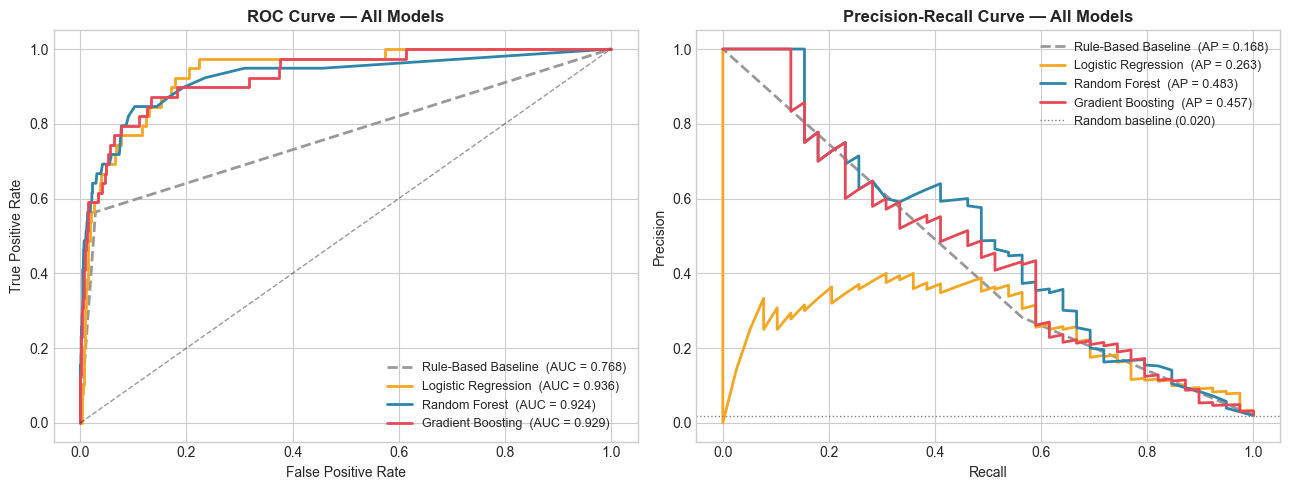

In [32]:
# Plot ROC and Precision-Recall curves for all four models on the same axes
model_styles = [
    (rule_prob, 'Rule-Based Baseline', '#999999', '--'),
    (yp_lr,    'Logistic Regression',  '#F5A623', '-'),
    (yp_rf,    'Random Forest',        '#2E86AB', '-'),
    (y_prob,   'Gradient Boosting',    '#E84855', '-'),
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for yp, label, col, ls in model_styles:
    fpr_m, tpr_m, _ = roc_curve(y_test, yp)
    ax1.plot(fpr_m, tpr_m, lw=2, ls=ls, color=col,
             label=f'{label}  (AUC = {roc_auc_score(y_test, yp):.3f})')
ax1.plot([0,1],[0,1], 'k--', lw=1, alpha=0.4)
ax1.set_xlabel('False Positive Rate'); ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve — All Models', fontweight='bold'); ax1.legend(fontsize=9)

for yp, label, col, ls in model_styles:
    p_m, r_m, _ = precision_recall_curve(y_test, yp)
    ax2.plot(r_m, p_m, lw=2, ls=ls, color=col,
             label=f'{label}  (AP = {average_precision_score(y_test, yp):.3f})')
ax2.axhline(y=y_test.mean(), color='gray', ls=':', lw=1,
            label=f'Random baseline ({y_test.mean():.3f})')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve — All Models', fontweight='bold'); ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

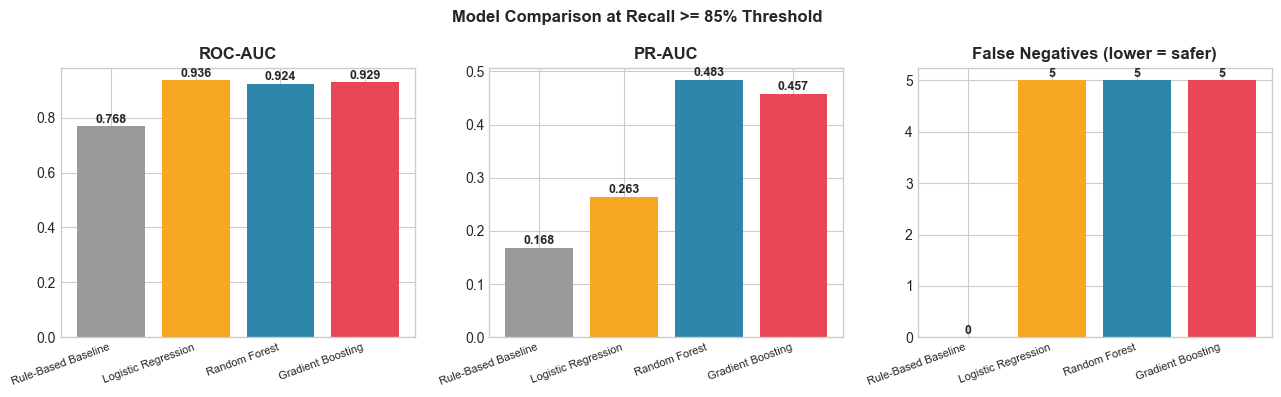

True Positives  (caught failures)    : 34
False Negatives (missed failures)    : 5  <- minimise this
False Positives (unnecessary alarms) : 262
True Negatives  (correct normal ops) : 1698


In [33]:
# Bar charts comparing ROC-AUC, PR-AUC and false negatives across all models
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
fig.suptitle('Model Comparison at Recall >= 85% Threshold', fontweight='bold', fontsize=12)

bar_cols = ['#999999', '#F5A623', '#2E86AB', '#E84855']
models   = results_df['Model'].tolist()

for ax, metric, label in zip(axes,
                              ['ROC-AUC', 'PR-AUC', 'FN'],
                              ['ROC-AUC', 'PR-AUC', 'False Negatives (lower = safer)']):
    vals = results_df[metric].tolist()
    bars = ax.bar(models, vals, color=bar_cols)
    ax.set_title(label, fontweight='bold')
    ax.set_xticklabels(models, rotation=20, ha='right', fontsize=8)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                str(v), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


cm = confusion_matrix(y_test, y_pred_tuned)
tn, fp, fn, tp = cm.ravel()
ratio = round(fp / tp, 1) if tp > 0 else 'N/A'

print(f'True Positives  (caught failures)    : {tp}')
print(f'False Negatives (missed failures)    : {fn}  <- minimise this')
print(f'False Positives (unnecessary alarms) : {fp}')
print(f'True Negatives  (correct normal ops) : {tn}')

### 3b Interpretation

| Model | ROC-AUC | PR-AUC | FN | FP | Verdict |
|---|---|---|---|---|---|
| Rule-Based Baseline | 0.768 | 0.168 | 0 | 1,960 | Catches every failure but flags the entire test set — unusable in practice |
| Logistic Regression | 0.936 | 0.263 | 5 | 299 | Best ROC-AUC overall — strong and interpretable |
| Random Forest | 0.924 | 0.483 | 5 | 327 | Highest PR-AUC but more false positives than LR and GBM |
| **Gradient Boosting** | **0.929** | **0.457** | **5** | **262** | **Fewest false positives — selected** |

All three ML models miss the same 5 failures (FN=5), so the differentiator is false positives
and ranking ability. Gradient Boosting is selected for producing the fewest false positives
(262) — fewer unnecessary callouts matters most in a real rig environment.

Worth noting: Logistic Regression leads on ROC-AUC (0.936) and is a strong second on false
positives (299). It would be the preferred choice if interpretability or deployment simplicity
were the top priority. Random Forest leads on PR-AUC (0.483) but its higher false positive
count (327) makes it the weaker practical choice here.

### 3.6 Summary of Results

| Metric | Value | Interpretation |
|---|---|---|
| ROC-AUC | **0.9289** | Strong ranking — model separates failure from normal reliably |
| PR-AUC | **0.4573** | 23x above the random baseline of 0.020 |
| Recall | **0.872** | 87% of genuine failures caught in the test period |
| Precision | **0.115** | About 1 in 9 alarms is a real failure — acceptable for safety |
| False Negatives | **5 / 39** | 5 failures missed across the full test window |
| False Positives | **262** | Unnecessary alarms — trigger inspection, not equipment damage |
| Threshold | **0.1337** | Tuned down from default 0.5 to prioritise recall over precision |

The model catches 34 out of 39 real failures in the test window. The threshold is set at 0.1337 — much lower than the default 0.5 — to reflect the asymmetry in costs between missed failures and false alarms. The feature engineering refinement — specifically dropping the redundant `temperature_roll_mean_10` column — reduced noise in the feature space without meaningfully affecting predictive power.